In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['mathtext.default'] = 'regular'
import scipy.stats


# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})


# functions to calculate statistics
def RMSE(actual, predicted):
    
    # Convert inputs to numpy arrays 
    actual = np.array(actual)
    predicted = np.array(predicted)
    
    # Calculate the squared differences
    squared_diff = (actual - predicted) ** 2
    
    # Compute the mean of squared differences
    mean_squared_diff = np.mean(squared_diff)
    
    # Take the square root of the mean squared difference
    return np.sqrt(mean_squared_diff)

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)

filenames = ['data_EXP_vs_SIM_rewBV2006_default_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewBV2006ang_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM9_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM9DH_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM9DH_scaled_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM10_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM10DH_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM10DH_scaled_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM11_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM11DH_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM11DH_scaled_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM12_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM12DH_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM12DH_scaled_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM14_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM14DH_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM14DH_scaled_PF_Nguyen_2018'
             ]
models = ['BV2006', 'BV2006ang', 'M9', 'M9DH', 'M9DH_scaled', 'M10', 'M10DH', 'M10DH_scaled',   
          'M11', 'M11DH', 'M11DH_scaled', 'M12', 'M12DH', 'M12DH_scaled', 'M14', 'M14DH', 'M14DH_scaled']

datasets = [pd.read_csv(f"../../output_results/{file}.csv", index_col=0) for file in filenames]




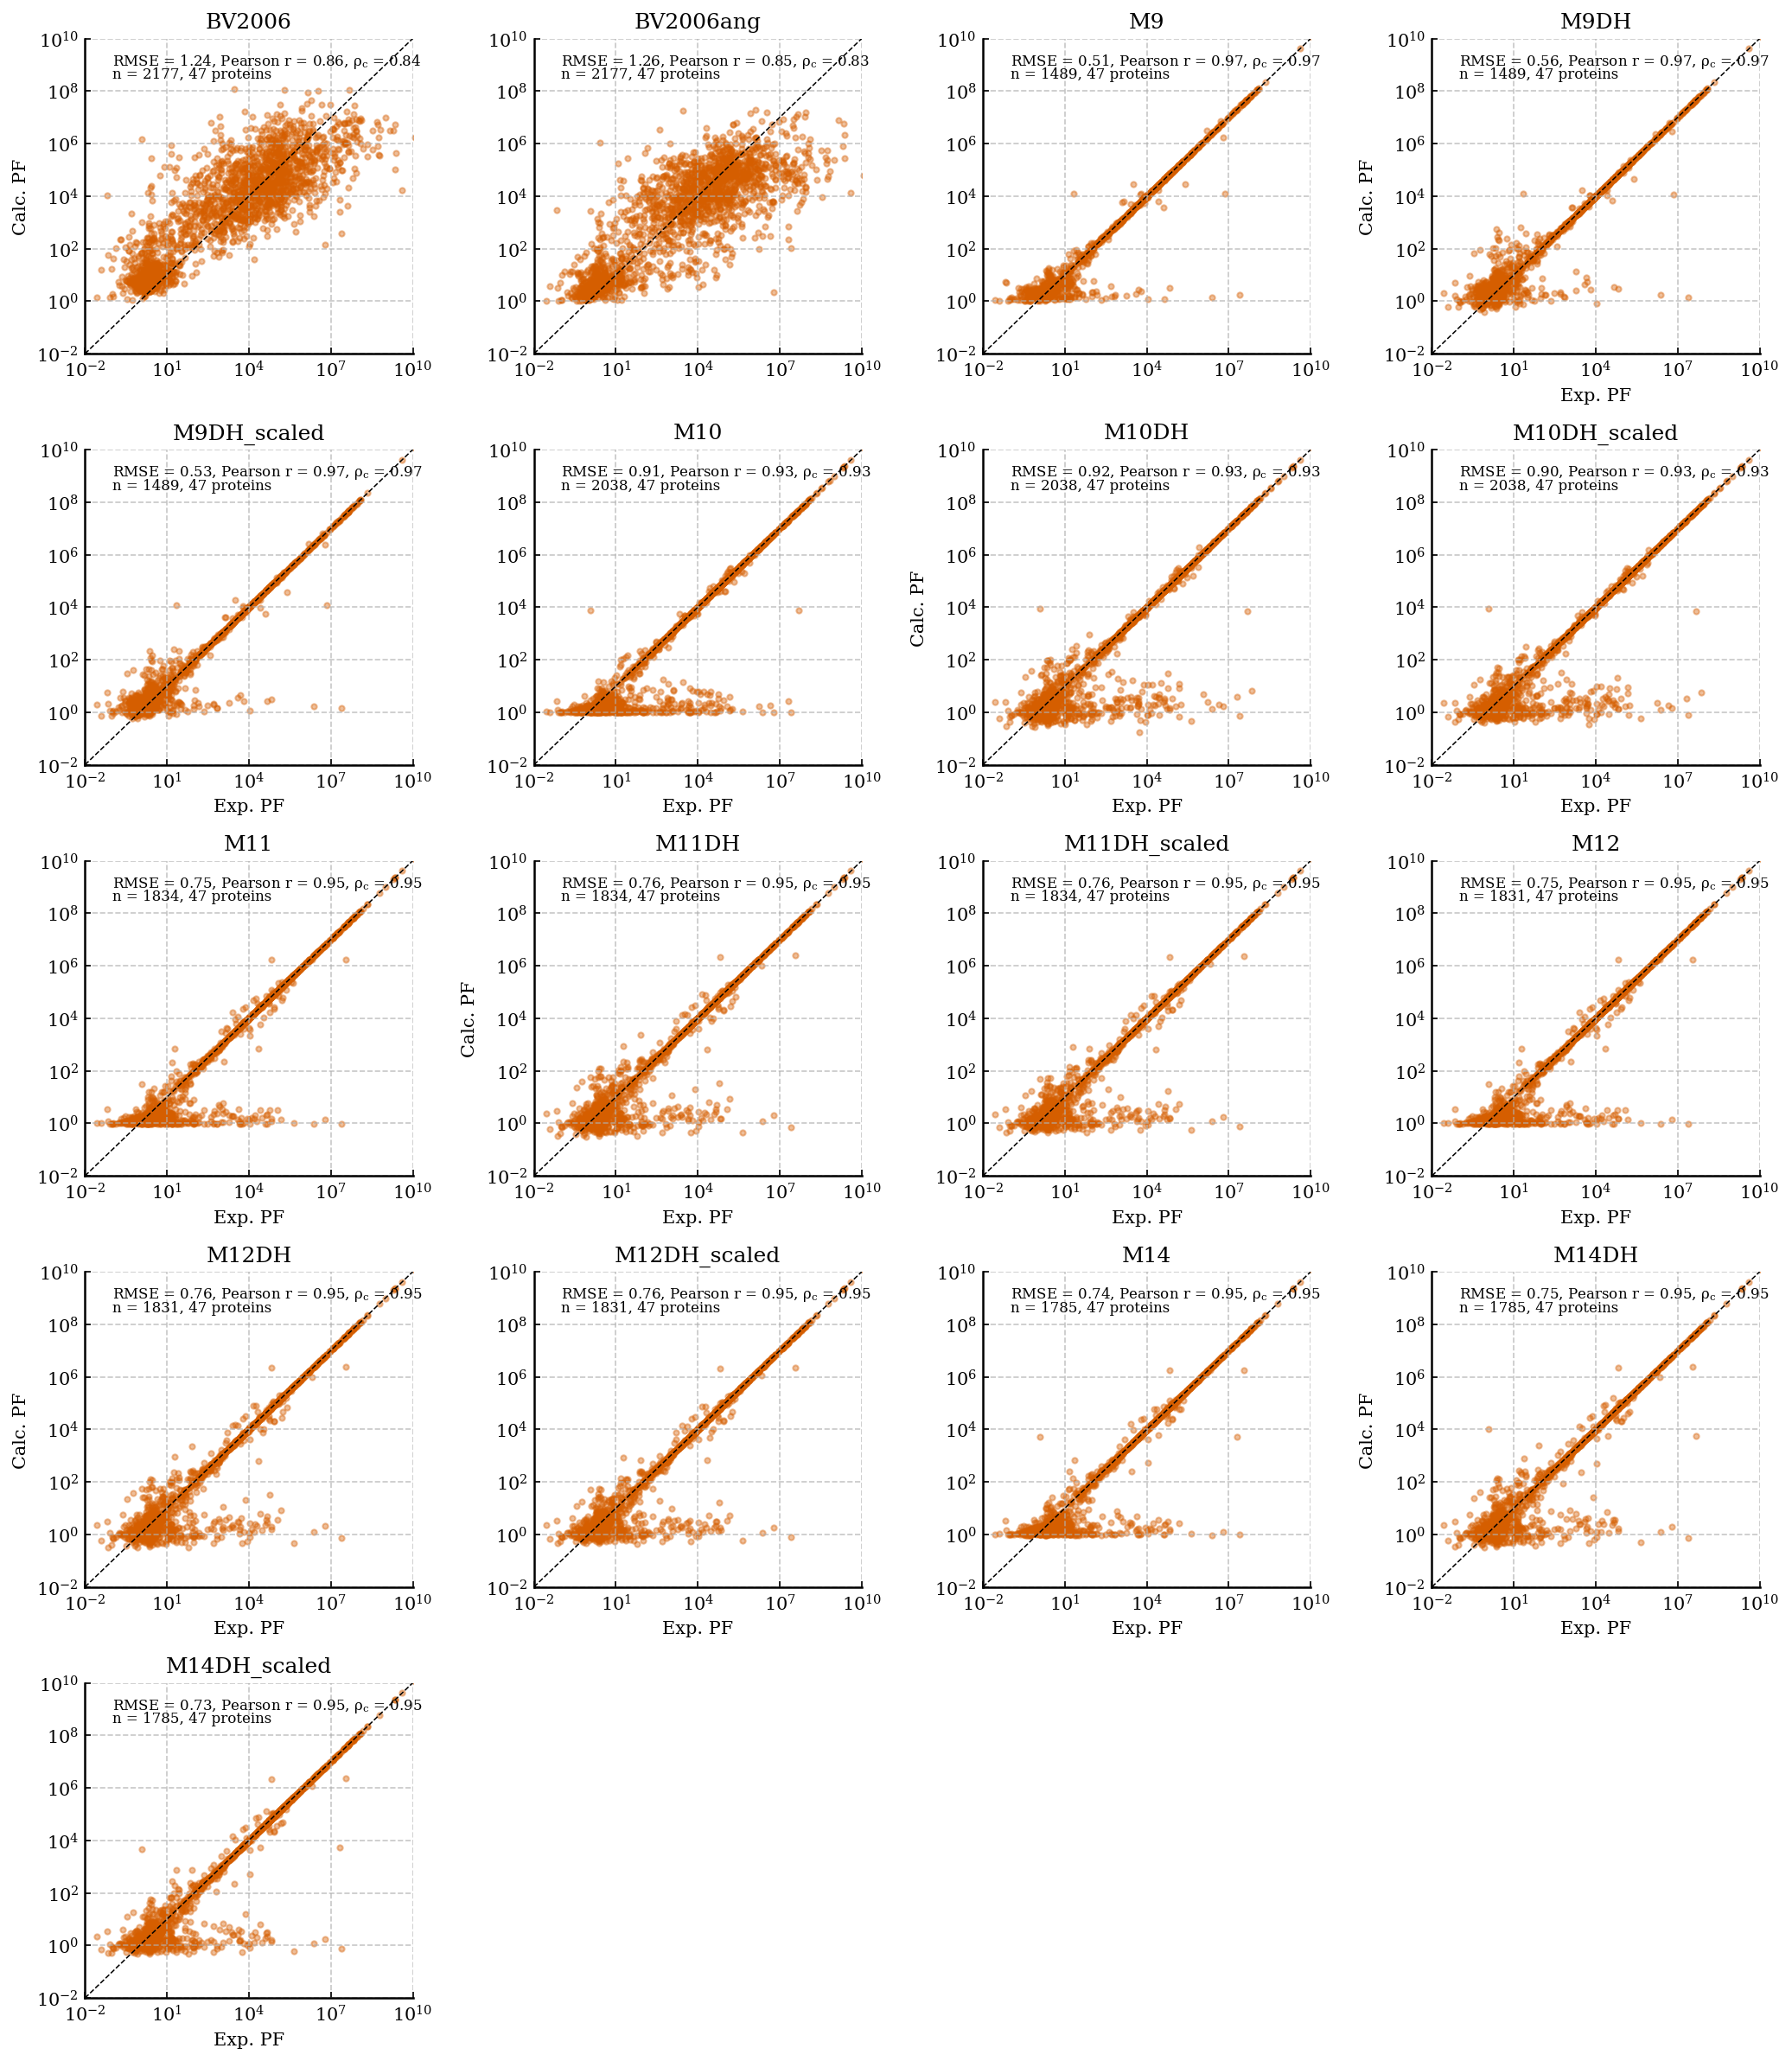

In [14]:
# Make a grid of subplots (5 rows × 4 columns, adjust if needed)
fig, axes = plt.subplots(5, 4, figsize=(14, 16))
axes = axes.flatten()

for ax, data, model_name in zip(axes, datasets, models):

    # ---- Scatter plot ----
    ax.scatter(data['EXP PF'], data['SIM PF'], color='#D55E00', alpha=0.4, s=9, rasterized=True)

    # ---- Stats ----
    log_exp = np.log10(data['EXP PF'])
    log_sim = np.log10(data['SIM PF'])
    r = scipy.stats.pearsonr(log_exp, log_sim)[0]
    rmse = RMSE(log_exp, log_sim)
    ccc = calc_ccc(log_exp, log_sim)

    proteins = np.unique(np.array(data['Protein']))
    n = len(data)

    # ---- Identity line ----
    x = np.linspace(1e-2, 1e10, 200)
    ax.plot(x, x, color='black', linestyle='dashed', linewidth=0.75)

    # ---- Log scaling and limits ----
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10)
    ax.set_ylim(1e-2, 1e10)

    # ---- Remove top and right axis lines and ticks ----
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    # ---- Labels only on left and bottom subplots ----
    if ax in axes[3:]:  # bottom row
        ax.set_xlabel("Exp. PF")
    if ax in axes[::3]:  # left column
        ax.set_ylabel("Calc. PF")

    # ---- Title ----
    ax.set_title(model_name)

    # ---- Text annotations ----
    ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, Pearson $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}", fontsize=8)
    ax.text(1e-1, 10**8.5, f"n = {int(n)}, {len(proteins)} proteins", fontsize=8)

# Remove any unused subplots if filenames < number of grid cells
for j in range(len(datasets), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('HDX_reweighting_models.pdf', dpi=300)

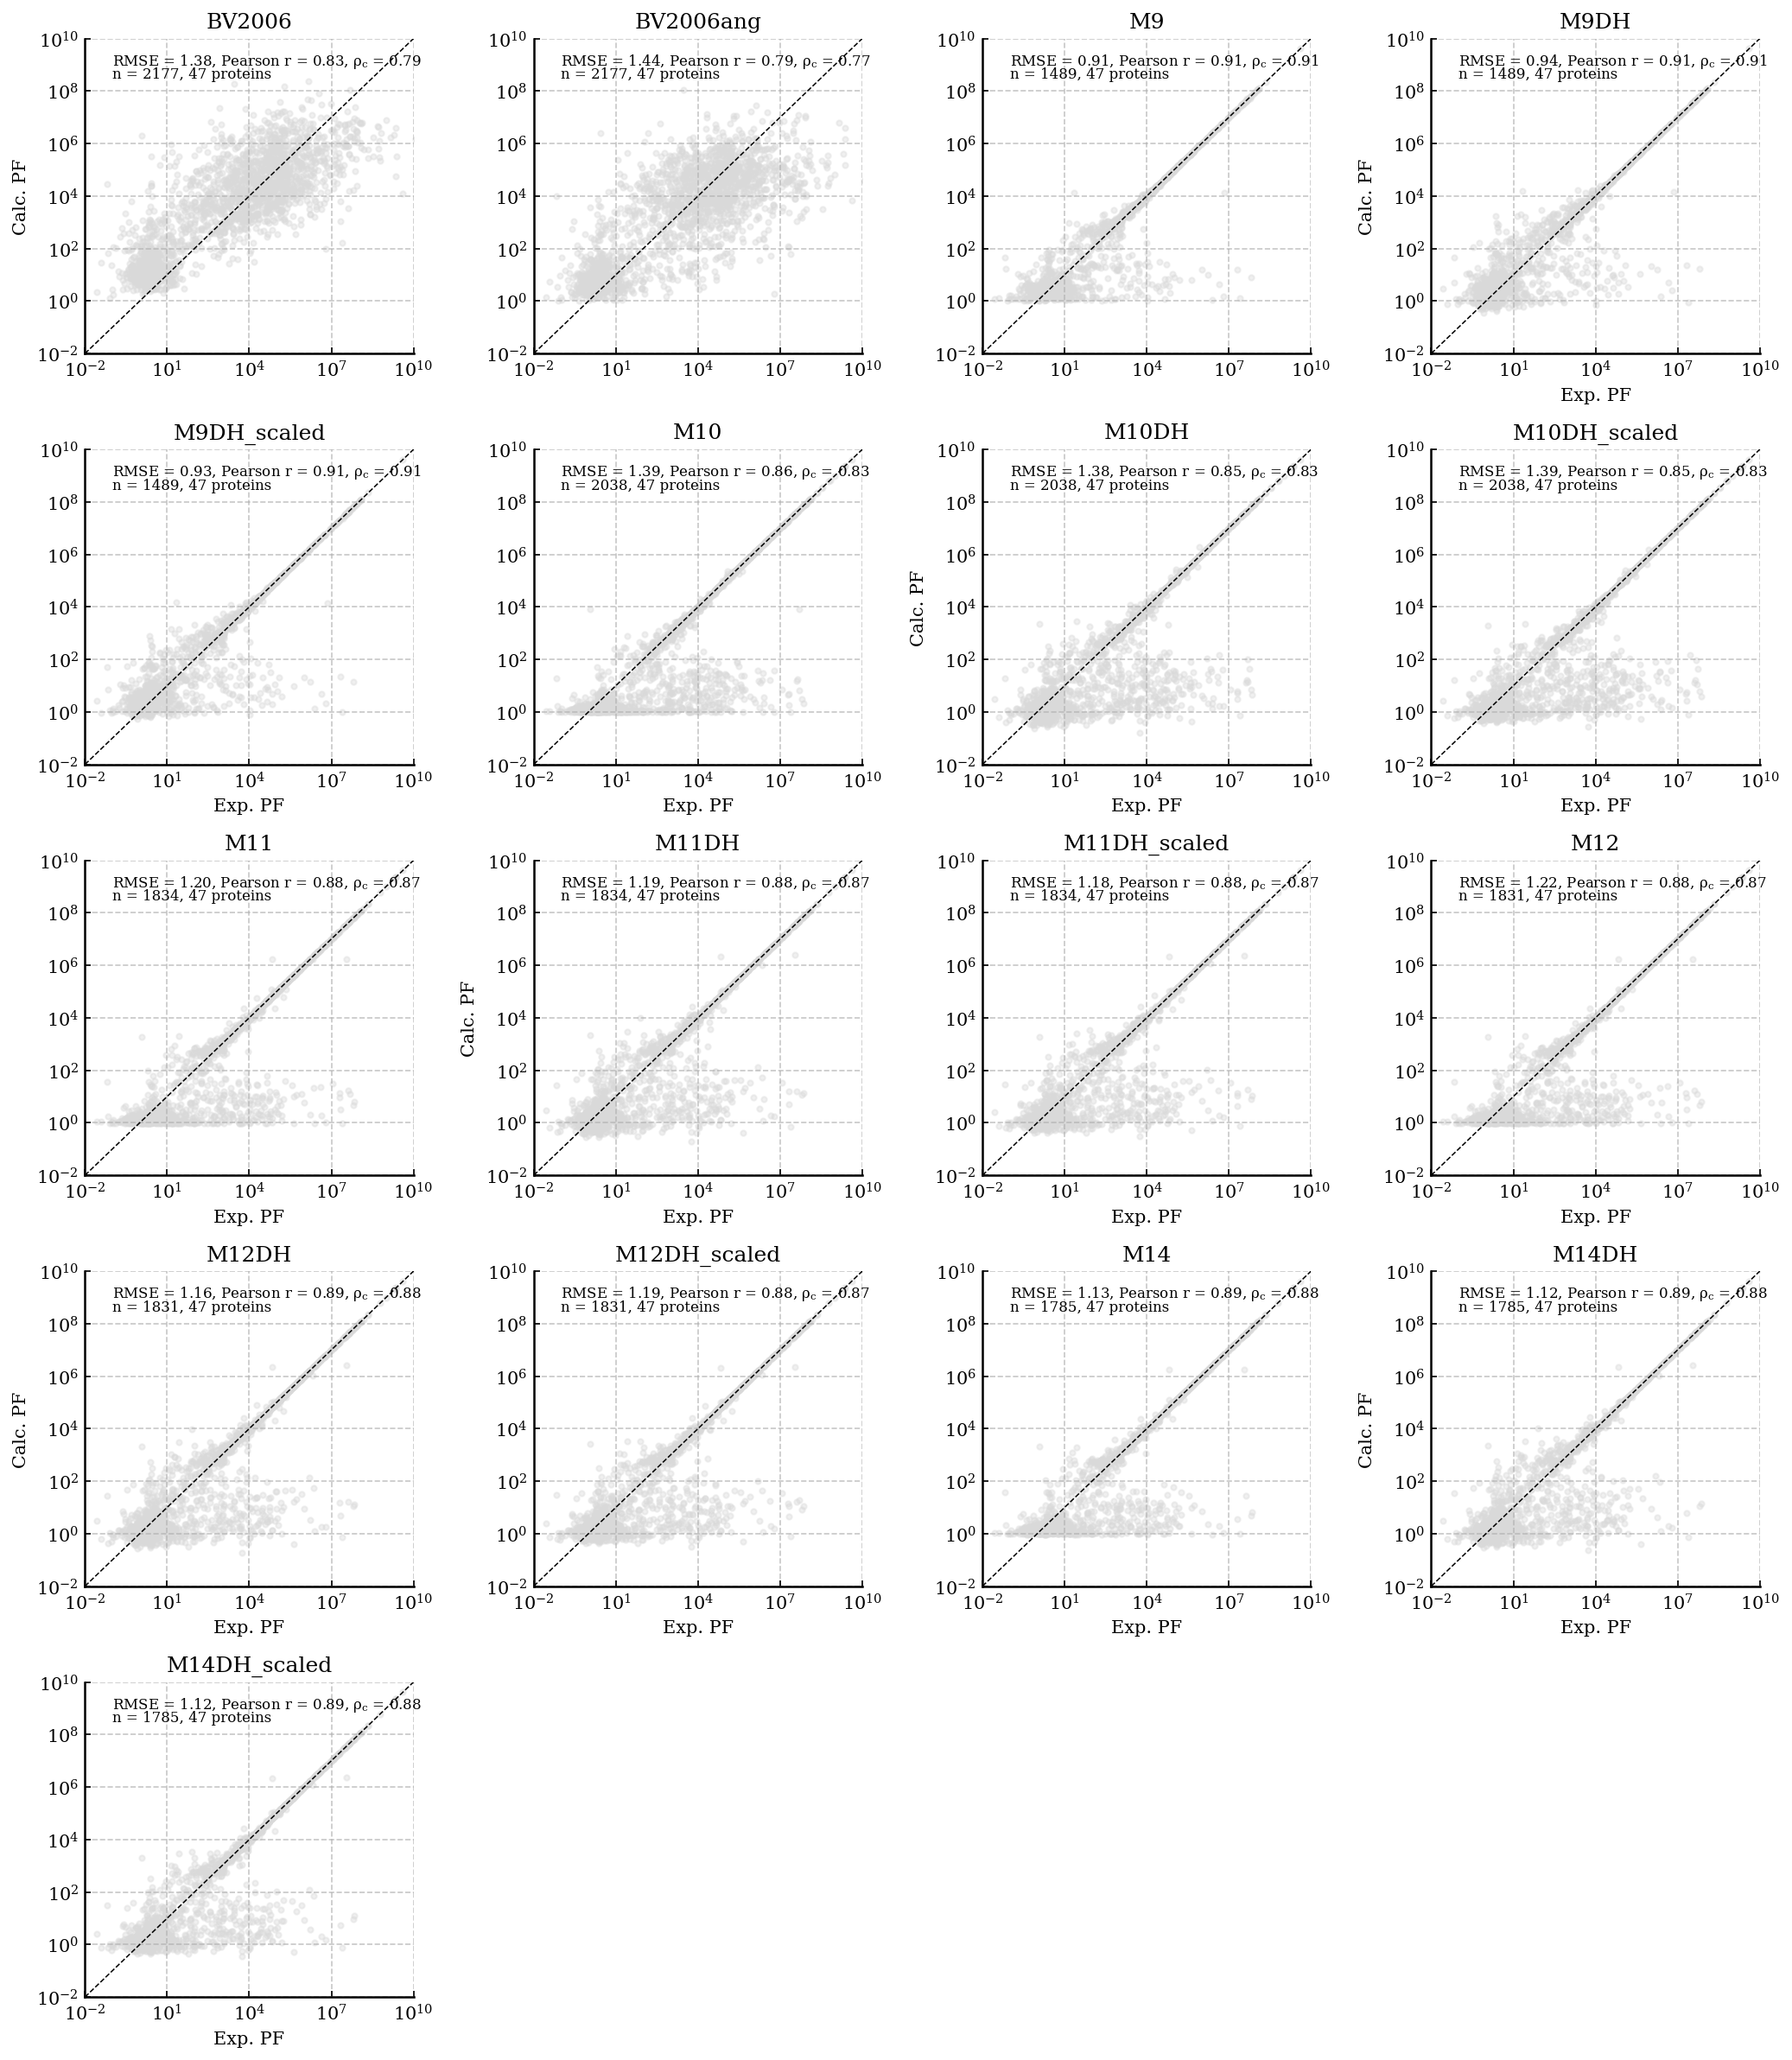

In [15]:
# Make a grid of subplots (5 rows × 4 columns, adjust if needed)
fig, axes = plt.subplots(5, 4, figsize=(14, 16))
axes = axes.flatten()

for ax, data, model_name in zip(axes, datasets, models):

    # ---- Scatter plot ----
    ax.scatter(data['EXP PF'], data['SIM PF ELBOW'], color='#D9D9D9', alpha=0.4, s=9, rasterized = True)

    # ---- Stats ----
    log_exp = np.log10(data['EXP PF'])
    log_sim = np.log10(data['SIM PF ELBOW'])
    r = scipy.stats.pearsonr(log_exp, log_sim)[0]
    rmse = RMSE(log_exp, log_sim)
    ccc = calc_ccc(log_exp, log_sim)

    proteins = np.unique(np.array(data['Protein']))
    n = len(data)

    # ---- Identity line ----
    x = np.linspace(1e-2, 1e10, 200)
    ax.plot(x, x, color='black', linestyle='dashed', linewidth=0.75)

    # ---- Log scaling and limits ----
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10)
    ax.set_ylim(1e-2, 1e10)

    # ---- Remove top and right axis lines and ticks ----
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    # ---- Labels only on left and bottom subplots ----
    if ax in axes[3:]:  # bottom row
        ax.set_xlabel("Exp. PF")
    if ax in axes[::3]:  # left column
        ax.set_ylabel("Calc. PF")

    # ---- Title ----
    ax.set_title(model_name)

    # ---- Text annotations ----
    ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, Pearson $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}", fontsize=8)
    ax.text(1e-1, 10**8.5, f"n = {int(n)}, {len(proteins)} proteins", fontsize=8)

# Remove any unused subplots if filenames < number of grid cells
for j in range(len(datasets), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('HDX_reweighting_models_elbow.pdf', dpi=300)

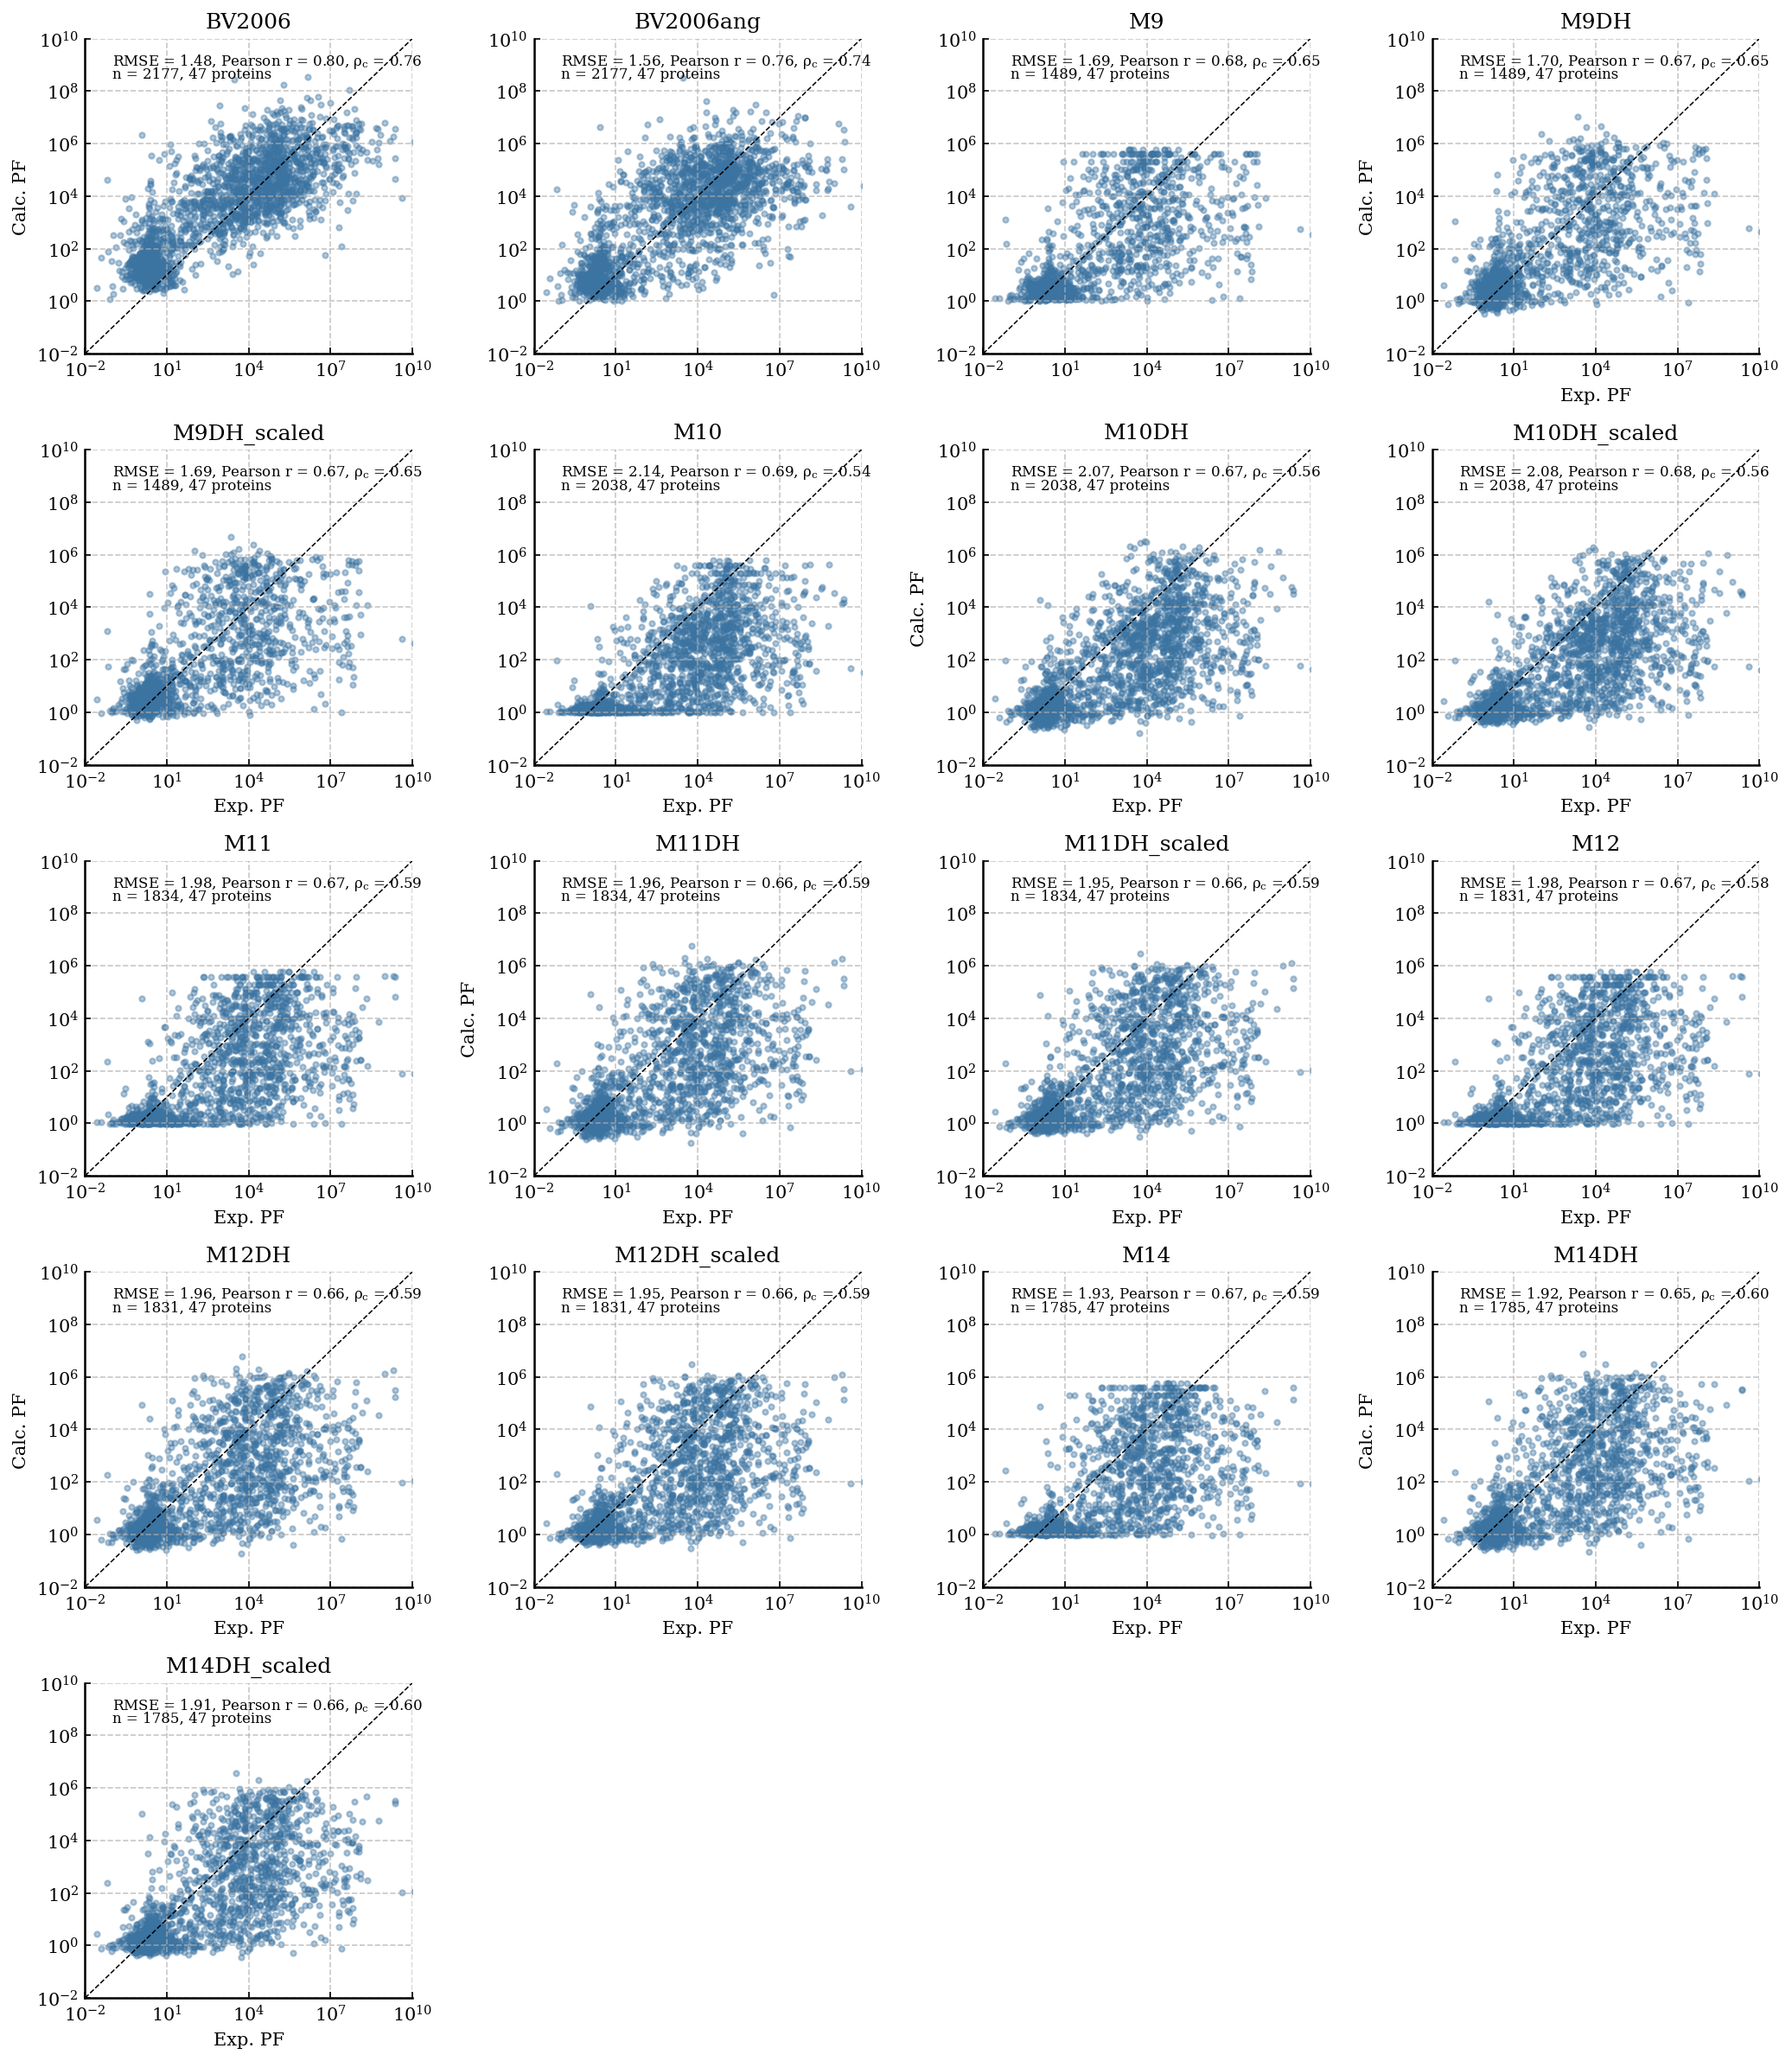

In [16]:
# Make a grid of subplots (5 rows × 4 columns, adjust if needed)
fig, axes = plt.subplots(5, 4, figsize=(14, 16))
axes = axes.flatten()

for ax, data, model_name in zip(axes, datasets, models):

    # ---- Scatter plot ----
    ax.scatter(data['EXP PF'], data['PRIOR SIM PF'], color='#3B73A1', alpha=0.4, s=9, rasterized=True)

    # ---- Stats ----
    log_exp = np.log10(data['EXP PF'])
    log_sim = np.log10(data['PRIOR SIM PF'])
    r = scipy.stats.pearsonr(log_exp, log_sim)[0]
    rmse = RMSE(log_exp, log_sim)
    ccc = calc_ccc(log_exp, log_sim)

    proteins = np.unique(np.array(data['Protein']))
    n = len(data)

    # ---- Identity line ----
    x = np.linspace(1e-2, 1e10, 200)
    ax.plot(x, x, color='black', linestyle='dashed', linewidth=0.75)

    # ---- Log scaling and limits ----
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10)
    ax.set_ylim(1e-2, 1e10)

    # ---- Remove top and right axis lines and ticks ----
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    # ---- Labels only on left and bottom subplots ----
    if ax in axes[3:]:  # bottom row
        ax.set_xlabel("Exp. PF")
    if ax in axes[::3]:  # left column
        ax.set_ylabel("Calc. PF")

    # ---- Title ----
    ax.set_title(model_name)

    # ---- Text annotations ----
    ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, Pearson $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}", fontsize=8)
    ax.text(1e-1, 10**8.5, f"n = {int(n)}, {len(proteins)} proteins", fontsize=8)

# Remove any unused subplots if filenames < number of grid cells
for j in range(len(datasets), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('HDX_reweighting_models_prior.pdf', dpi=300)

In [2]:
# barplot of this dataset
# RMSE, r, CCC (rho_c) for prior, elbow, final wopt
# have it vertical rather than horizontal

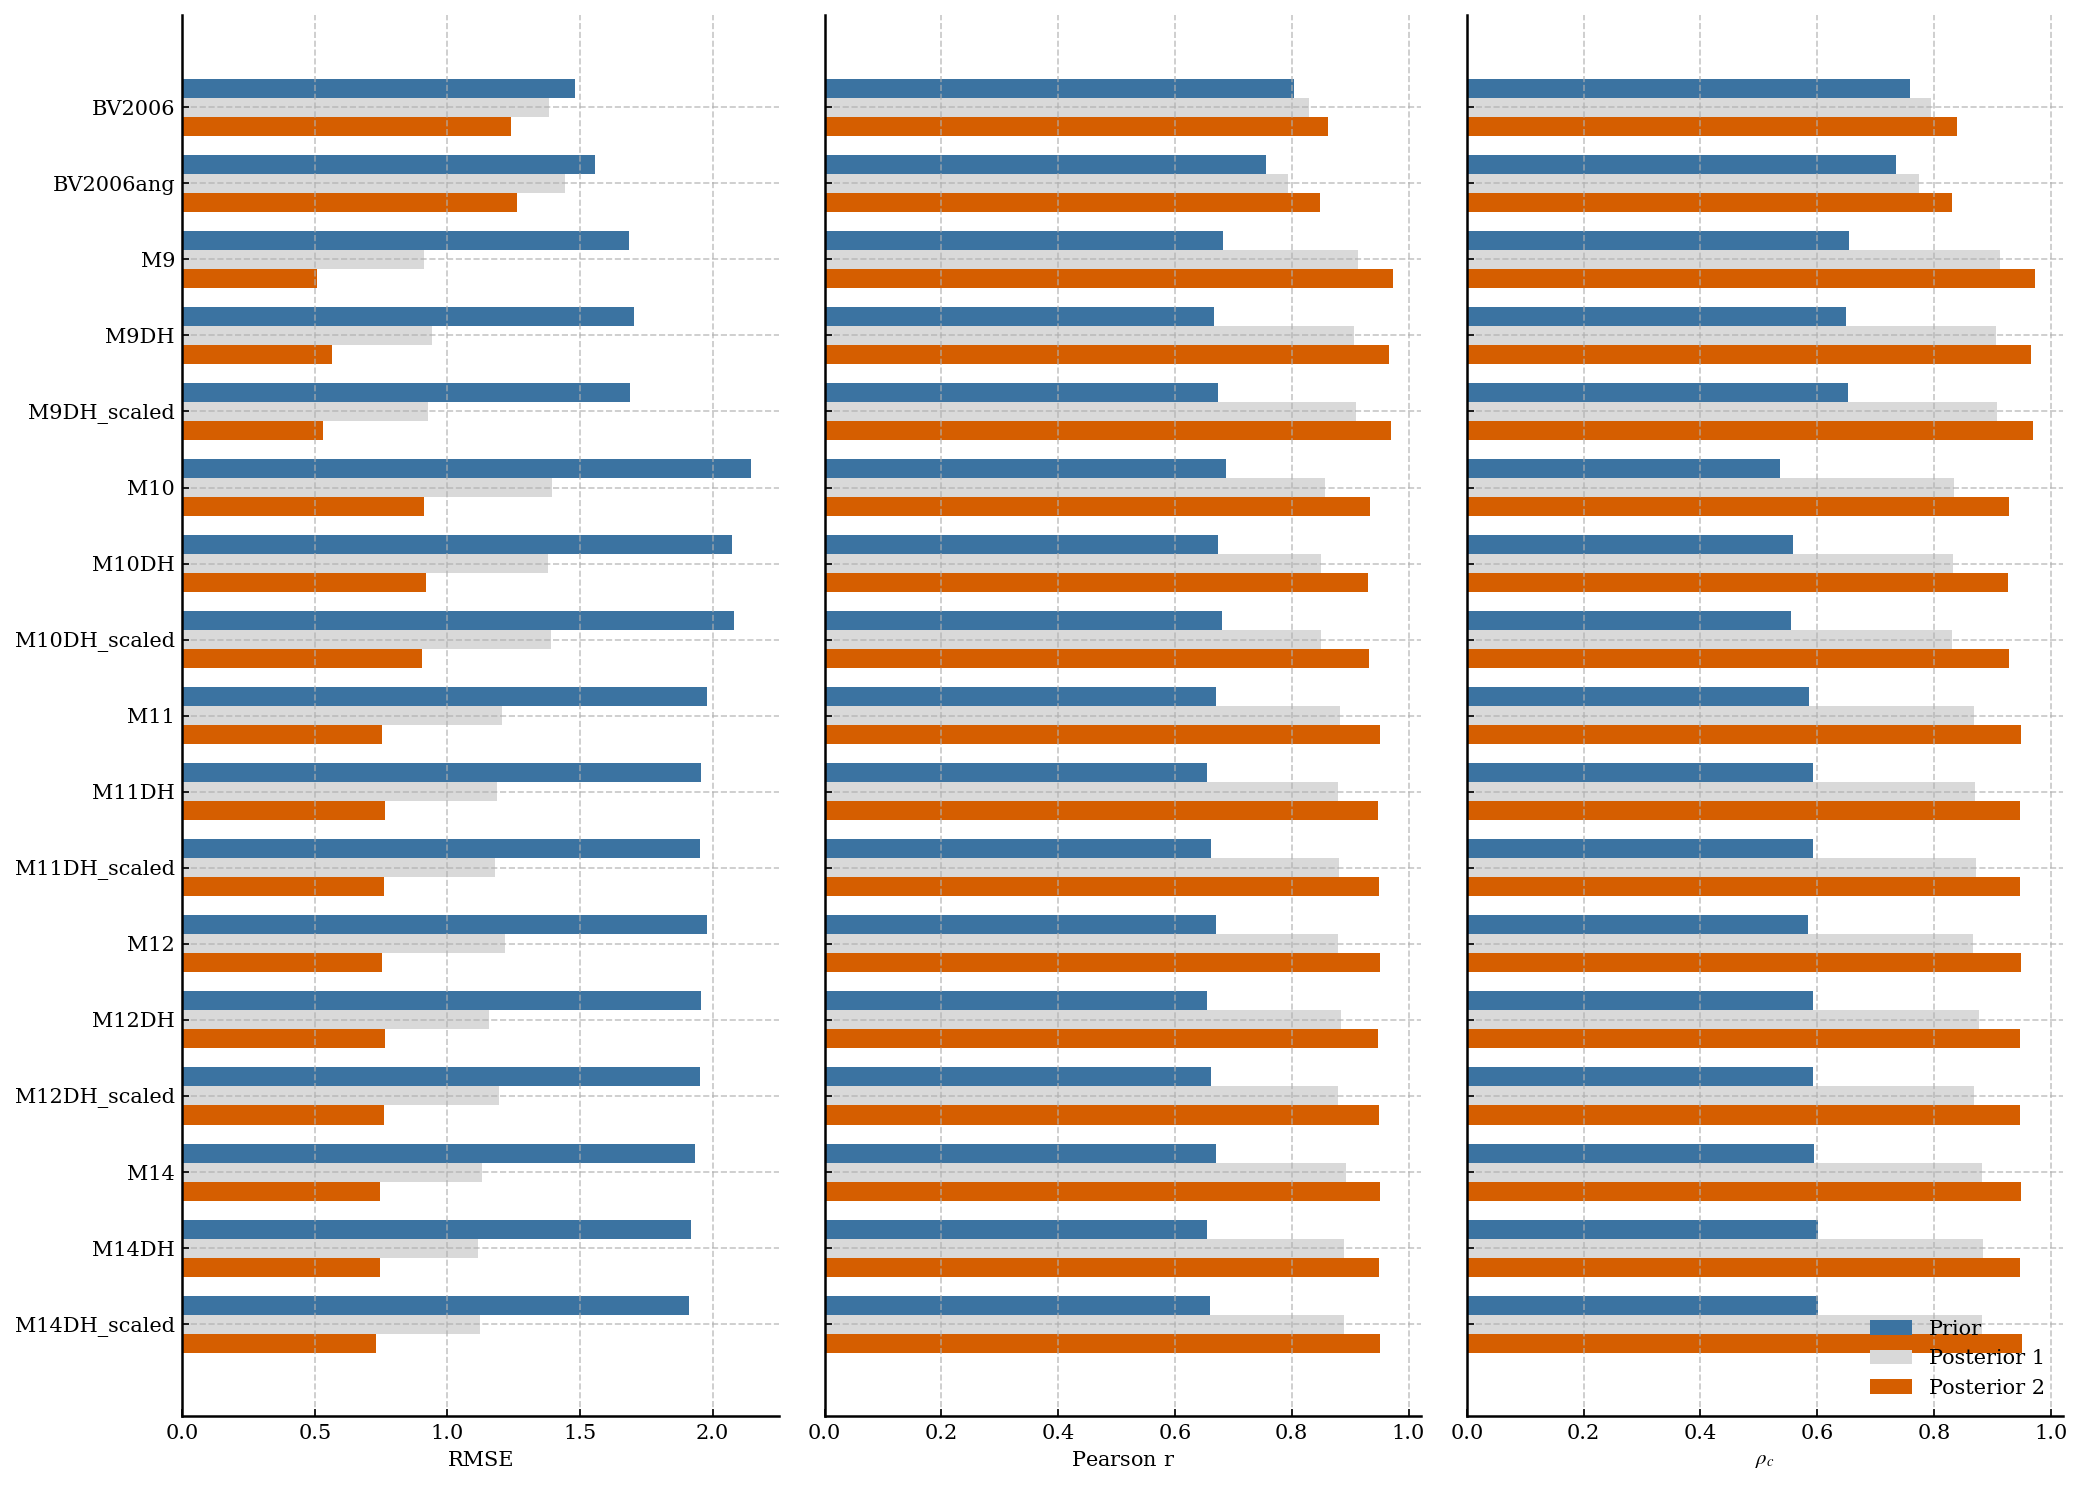

In [18]:


COLOR3 = "#3B73A1"  # deep muted blue
COLOR1 = "#D55E00"  # vermillion
COLOR2 = "#D9D9D9"

# ---- Compute stats for prior, posterior 1 (elbow), posterior 2 (final) ----
stages = {
    'Prior': 'PRIOR SIM PF',
    'Posterior 1': 'SIM PF ELBOW',
    'Posterior 2': 'SIM PF'
}

results = {stat: {stage: [] for stage in stages} for stat in ['RMSE', 'Pearson r', 'CCC']}

for data in datasets:
    exp_log = np.log10(data['EXP PF'])
    for stage_name, col in stages.items():
        sim_log = np.log10(data[col])
        results['RMSE'][stage_name].append(RMSE(exp_log, sim_log))
        results['Pearson r'][stage_name].append(scipy.stats.pearsonr(exp_log, sim_log)[0])
        results['CCC'][stage_name].append(calc_ccc(exp_log, sim_log))

# ---- Plot ----
fig, axes = plt.subplots(1, 3, figsize=(14, 10), sharey=True)

n_models = len(models)
n_stages = len(stages)
bar_height = 0.25
y = np.arange(n_models)
colors = {'Prior': COLOR3, 'Posterior 1': COLOR2, 'Posterior 2': COLOR1}

for ax, stat_name, xlabel in zip(axes, ['RMSE', 'Pearson r', 'CCC'], ['RMSE', 'Pearson $r$', r'$\mathit{\rho_c}$']):
    for i, stage_name in enumerate(stages):
        offset = (i - (n_stages - 1) / 2) * bar_height
        ax.barh(y + offset, results[stat_name][stage_name], height=bar_height, label=stage_name, color=colors[stage_name])

    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

axes[0].set_yticks(y)
axes[0].set_yticklabels(models)
axes[0].invert_yaxis()  # first model at top

axes[-1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('HDX_reweighting_models_summary_barplot_all.pdf', dpi=300)
plt.show()

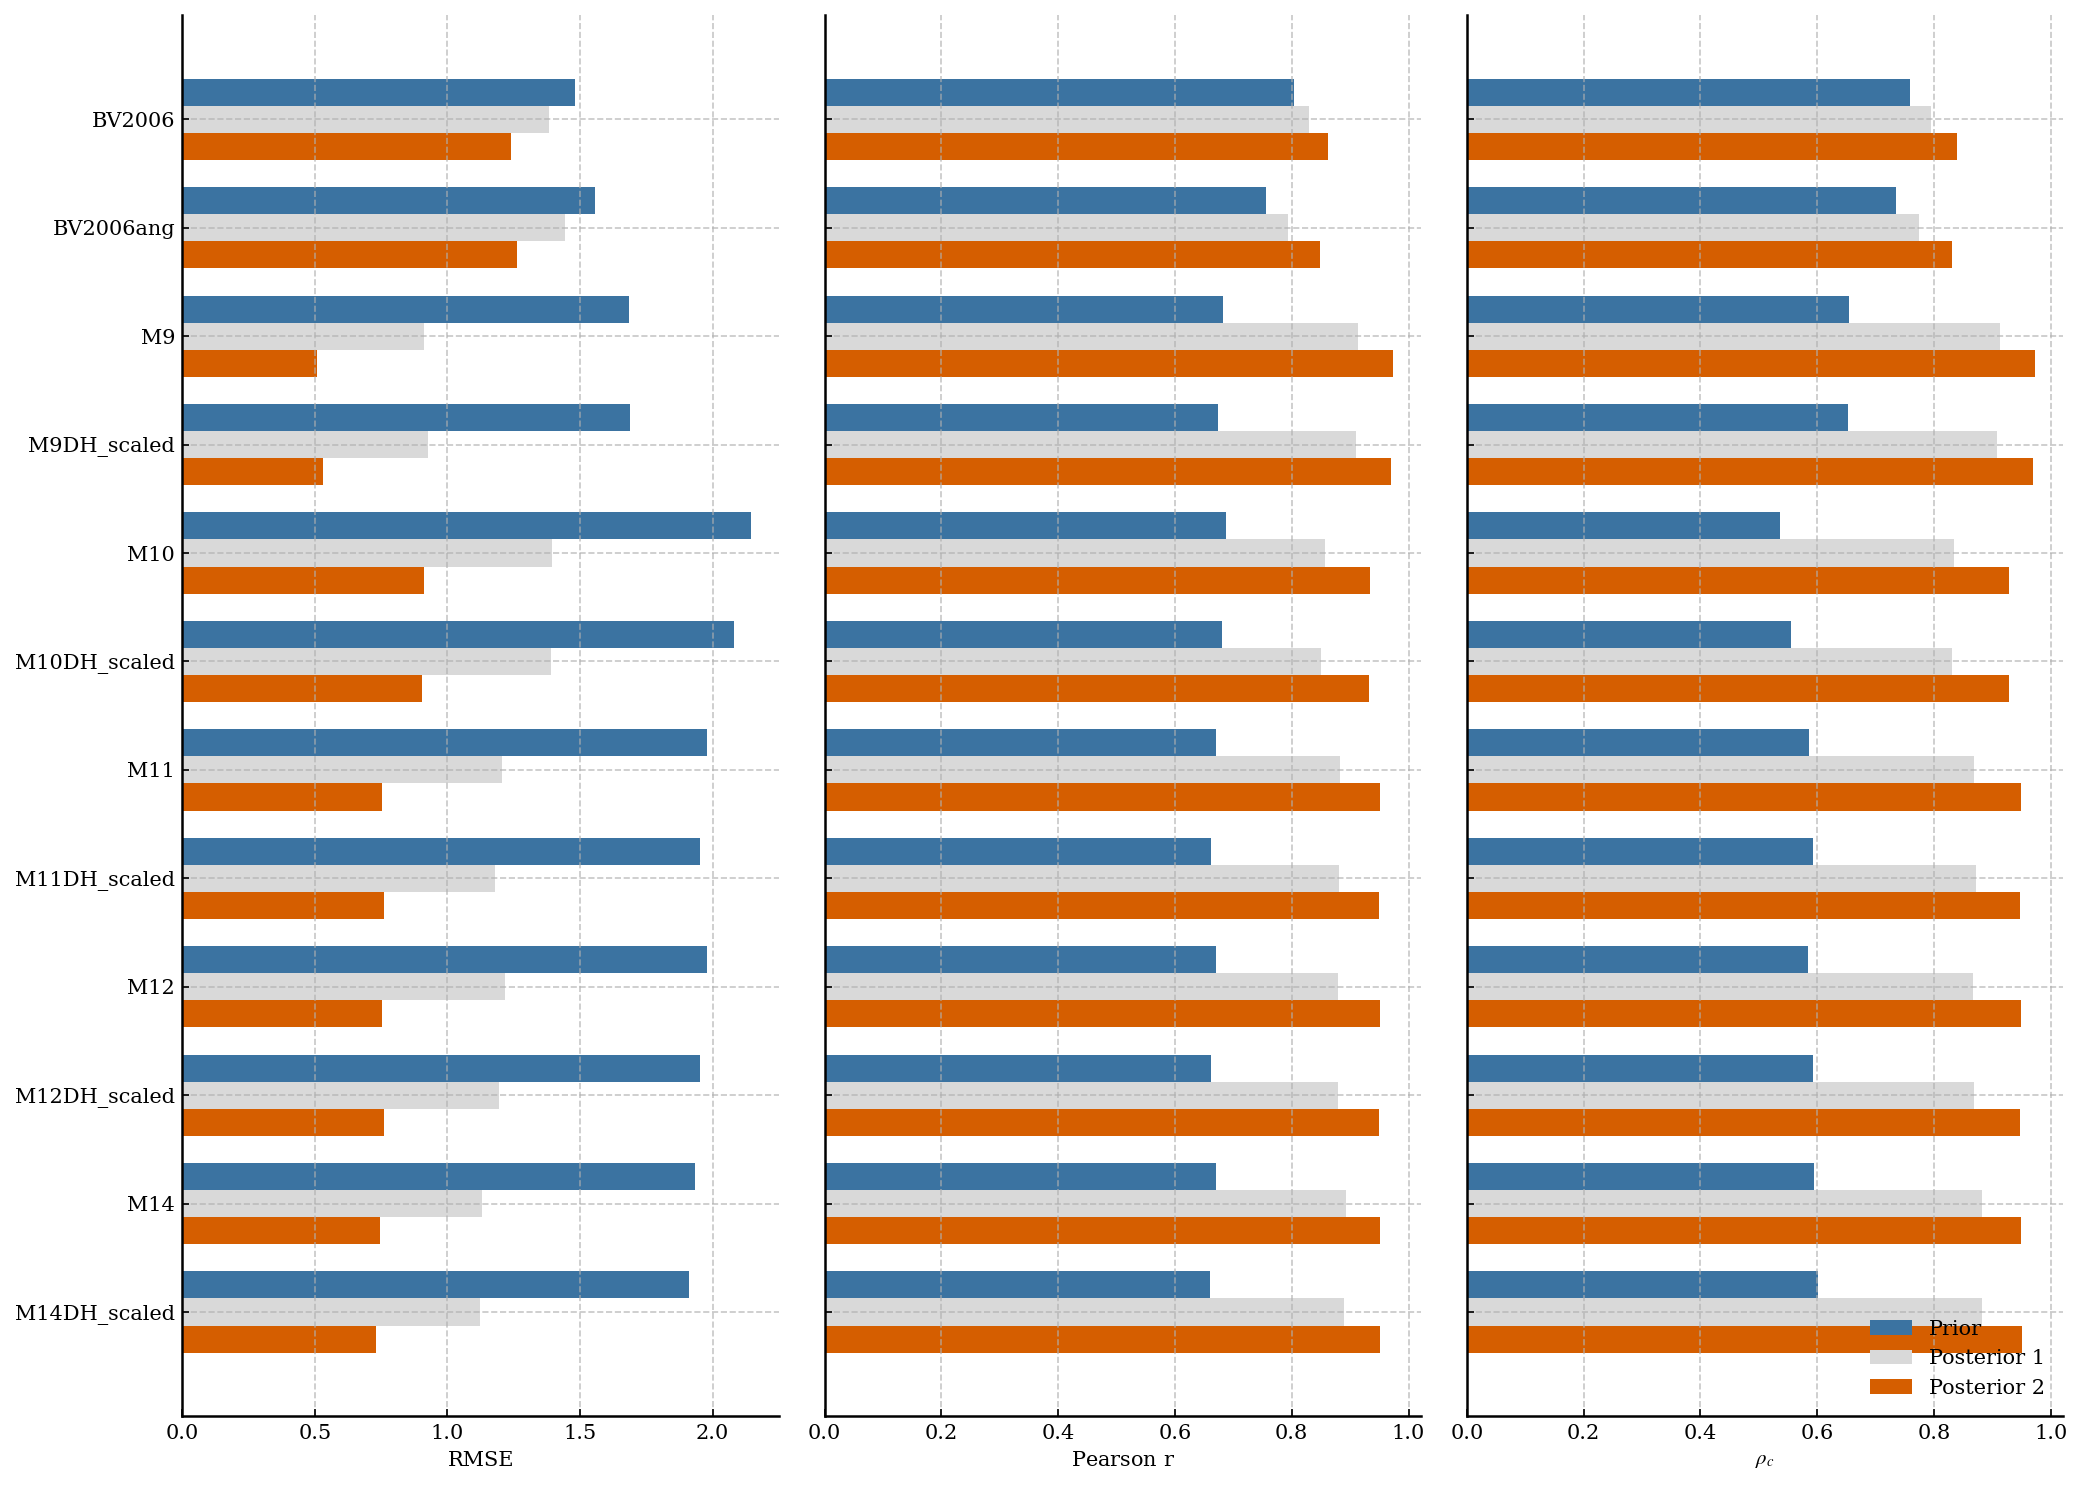

In [19]:
# subset of models
models = ['BV2006', 'BV2006ang', 'M9', 'M9DH_scaled', 'M10', 'M10DH_scaled',
          'M11', 'M11DH_scaled', 'M12', 'M12DH_scaled', 'M14', 'M14DH_scaled']

filenames = ['data_EXP_vs_SIM_rewBV2006_default_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewBV2006ang_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM9_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM9DH_scaled_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM10_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM10DH_scaled_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM11_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM11DH_scaled_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM12_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM12DH_scaled_PF_Nguyen_2018',
             'data_EXP_vs_SIM_rewM14_PF_Nguyen_2018', 'data_EXP_vs_SIM_rewM14DH_scaled_PF_Nguyen_2018']

datasets = [pd.read_csv(f"../../output_results/{file}.csv", index_col=0) for file in filenames]

COLOR3 = "#3B73A1"  # deep muted blue
COLOR1 = "#D55E00"  # vermillion
COLOR2 = "#D9D9D9"

# ---- Compute stats for prior, posterior 1 (elbow), posterior 2 (final) ----
stages = {
    'Prior': 'PRIOR SIM PF',
    'Posterior 1': 'SIM PF ELBOW',
    'Posterior 2': 'SIM PF'
}

results = {stat: {stage: [] for stage in stages} for stat in ['RMSE', 'Pearson r', 'CCC']}

for data in datasets:
    exp_log = np.log10(data['EXP PF'])
    for stage_name, col in stages.items():
        sim_log = np.log10(data[col])
        results['RMSE'][stage_name].append(RMSE(exp_log, sim_log))
        results['Pearson r'][stage_name].append(scipy.stats.pearsonr(exp_log, sim_log)[0])
        results['CCC'][stage_name].append(calc_ccc(exp_log, sim_log))

# ---- Plot ----
fig, axes = plt.subplots(1, 3, figsize=(14, 10), sharey=True)

n_models = len(models)
n_stages = len(stages)
bar_height = 0.25
y = np.arange(n_models)
colors = {'Prior': COLOR3, 'Posterior 1': COLOR2, 'Posterior 2': COLOR1}

for ax, stat_name, xlabel in zip(axes, ['RMSE', 'Pearson r', 'CCC'], ['RMSE', 'Pearson $r$', r'$\mathit{\rho_c}$']):
    for i, stage_name in enumerate(stages):
        offset = (i - (n_stages - 1) / 2) * bar_height
        ax.barh(y + offset, results[stat_name][stage_name], height=bar_height, label=stage_name, color=colors[stage_name])

    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

axes[0].set_yticks(y)
axes[0].set_yticklabels(models)
axes[0].invert_yaxis()  # first model at top

axes[-1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('HDX_reweighting_models_summary_barplot.pdf', dpi=300)
plt.show()

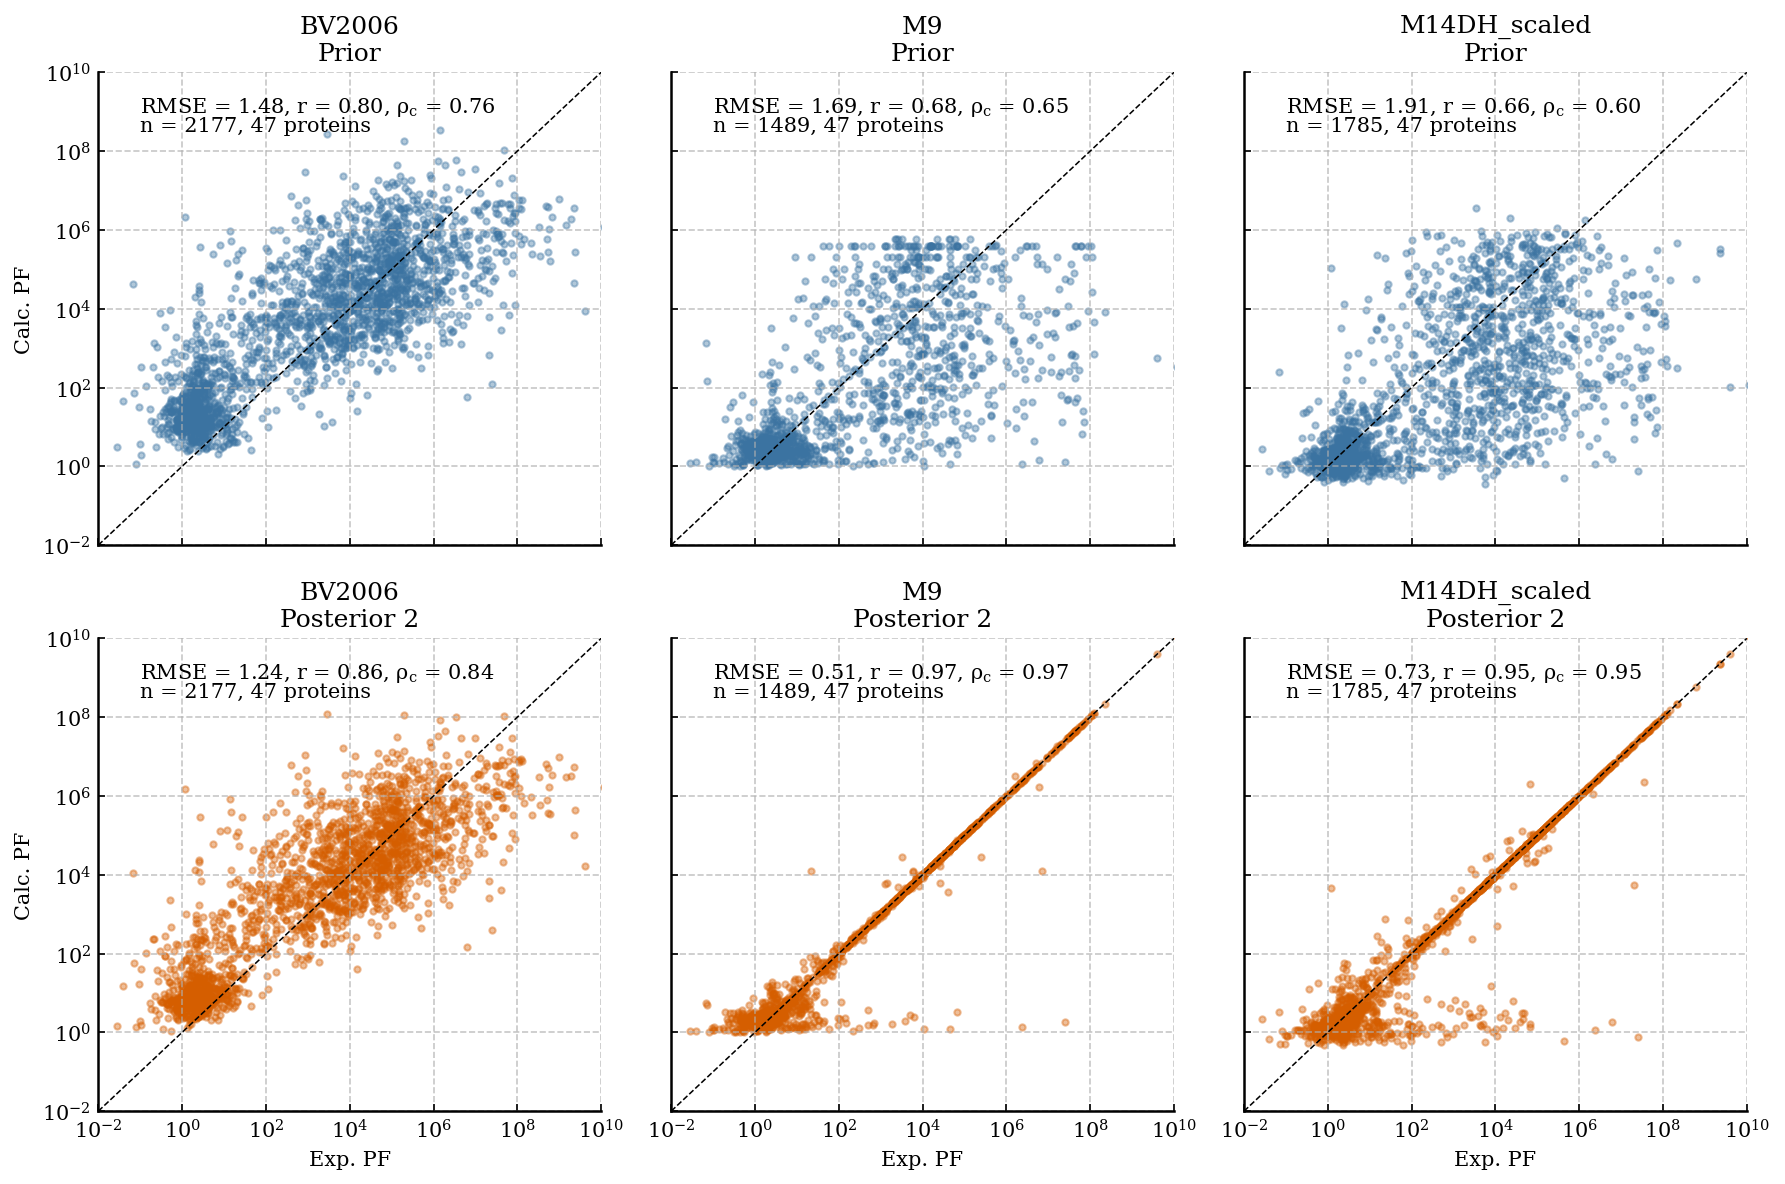

In [3]:
filenames = [
    'data_EXP_vs_SIM_rewBV2006_default_PF_Nguyen_2018',
    'data_EXP_vs_SIM_rewM9_PF_Nguyen_2018',
    'data_EXP_vs_SIM_rewM14DH_scaled_PF_Nguyen_2018'
]

models = ['BV2006', 'M9', 'M14DH_scaled']

datasets = [pd.read_csv(f"../../output_results/{file}.csv", index_col=0) for file in filenames]

# --------------------------------------------------
# Colours
# --------------------------------------------------
PRIOR_COLOR = "#3B73A1"
POSTERIOR_COLOR = "#D55E00"

# --------------------------------------------------
# Create 2 × 3 subplot grid
# Top row: prior
# Bottom row: posterior
# --------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)

identity_values = np.logspace(-2, 10, 200)

for col, (data, model_name) in enumerate(zip(datasets, models)):

    proteins = np.unique(data['Protein'])
    n = len(data)

    exp_log_pf = np.log10(data['EXP PF'])

    # --------------------------------------------------
    # Top row: prior
    # --------------------------------------------------
    ax = axes[0, col]

    prior_log_pf = np.log10(data['PRIOR SIM PF'])

    ax.scatter(data['EXP PF'], data['PRIOR SIM PF'], color=PRIOR_COLOR, alpha=0.4, s=9, rasterized=True)

    prior_r = scipy.stats.pearsonr(exp_log_pf, prior_log_pf)[0]
    prior_rmse = RMSE(exp_log_pf, prior_log_pf)
    prior_ccc = calc_ccc(exp_log_pf, prior_log_pf)

    ax.plot(identity_values, identity_values, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10)
    ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_name}\nPrior")

    ax.text(1e-1, 1e9, rf"RMSE = {prior_rmse:.2f}, $r$ = {prior_r:.2f}, $\rho_c$ = {prior_ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {n}, {len(proteins)} proteins")

    if col == 0:
        ax.set_ylabel("Calc. PF")

    # --------------------------------------------------
    # Bottom row: posterior
    # --------------------------------------------------
    ax = axes[1, col]

    posterior_log_pf = np.log10(data['SIM PF'])

    ax.scatter(data['EXP PF'], data['SIM PF'], color=POSTERIOR_COLOR, alpha=0.4, s=9, rasterized=True)

    posterior_r = scipy.stats.pearsonr(exp_log_pf, posterior_log_pf)[0]
    posterior_rmse = RMSE(exp_log_pf, posterior_log_pf)
    posterior_ccc = calc_ccc(exp_log_pf, posterior_log_pf)

    ax.plot(identity_values, identity_values, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10)
    ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_name}\nPosterior 2")

    ax.text(1e-1, 1e9, rf"RMSE = {posterior_rmse:.2f}, $r$ = {posterior_r:.2f}, $\rho_c$ = {posterior_ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {n}, {len(proteins)} proteins")

    ax.set_xlabel("Exp. PF")

    if col == 0:
        ax.set_ylabel("Calc. PF")

plt.tight_layout()
plt.savefig('HDX_reweighting_selected_models_prior_posterior.pdf', dpi=300, bbox_inches='tight')
plt.show()